# PPG-DaLiA — 01. Exploratory Data Analysis

**Goal:** Explore the participants first, choose one, and inspect their wrist PPG and accelerometer signals. No heart-rate model is built here.

The dataset contains 15 participants, wrist BVP/PPG (64 Hz), wrist accelerometer (32 Hz), and ECG-derived reference heart-rate labels (8-second windows, shifted by 2 seconds).

Sources: [UCI PPG-DaLiA](https://archive.ics.uci.edu/dataset/495/ppg-dalia) · [Original paper](https://doi.org/10.3390/s19143079).

## 1. Meet the participants

The following small table comes from the **published PPG-DaLiA participant characteristics** ([Papaleonidas et al., Table 2](https://doi.org/10.1080/24751839.2021.1987706)). It is included here so you can compare the 15 subjects **before loading a large `.pkl` file**.

- **Skin type:** Fitzpatrick classification reported by the study.
- **Fitness:** 1–6 (1 = exercises less than once/month; 6 = exercises 5–7 times/week).

These are reported participant attributes, not values measured by the wrist sensors.

In [114]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Subject metadata transcribed from the published dataset table.
subjects = pd.DataFrame([
    ["S1",  "Male",   34, 182,  78, 3, 6],
    ["S2",  "Male",   28, 189,  80, 3, 5],
    ["S3",  "Male",   25, 170,  60, 3, 5],
    ["S4",  "Male",   25, 168,  57, 4, 5],
    ["S5",  "Female", 21, 180,  70, 3, 4],
    ["S6",  "Female", 37, 176,  70, 3, 1],
    ["S7",  "Female", 21, 168,  58, 3, 2],
    ["S8",  "Male",   43, 179,  70, 3, 5],
    ["S9",  "Female", 28, 167,  60, 4, 5],
    ["S10", "Female", 55, 164,  56, 4, 5],
    ["S11", "Female", 24, 168,  62, 3, 5],
    ["S12", "Male",   43, 195, 105, 3, 5],
    ["S13", "Female", 21, 170,  63, 3, 6],
    ["S14", "Female", 26, 170,  67, 3, 4],
    ["S15", "Male",   28, 183,  79, 2, 5],
], columns=["Subject", "Gender", "Age", "Height (cm)", "Weight (kg)", "Skin type", "Fitness"])

display(subjects)
print(f"Subjects: {len(subjects)}")
print(f"Age: {subjects['Age'].min()}–{subjects['Age'].max()} years (median {subjects['Age'].median():.0f})")
print("Gender distribution:")
print(subjects["Gender"].value_counts().to_string())


# Notes:
# - our skin is typically 3, 4. so this dataset is good for that
# - I'll focus more on younger subjects, as those are more closely related to our product.
# - There are more male kids than female kids, so I'll test more males.

# based on that, S3 and S4 are the best candidates
# wl 7lw en el nas dyh m3ndhash mshakel, fy nas tanya gehazha baz
# fy nas m3mletsh el tadreeb kamel

,Subject,Gender,Age,Height (cm),Weight (kg),Skin type,Fitness
0,S1,Male,34,182,78,3,6
1,S2,Male,28,189,80,3,5
2,S3,Male,25,170,60,3,5
3,S4,Male,25,168,57,4,5
4,S5,Female,21,180,70,3,4
5,S6,Female,37,176,70,3,1
6,S7,Female,21,168,58,3,2
7,S8,Male,43,179,70,3,5
8,S9,Female,28,167,60,4,5
9,S10,Female,55,164,56,4,5


Subjects: 15
Age: 21–55 years (median 28)
Gender distribution:
Gender
Female    8
Male      7


### Age and gender distributions

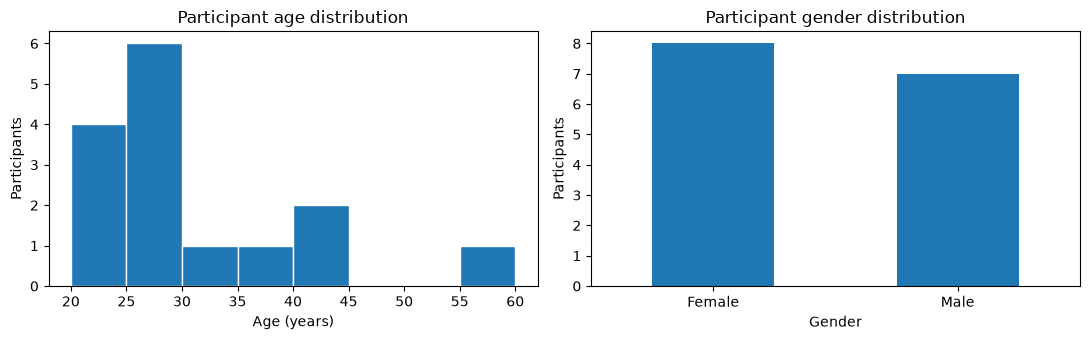

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].hist(subjects["Age"], bins=range(20, 61, 5), edgecolor="white")
axes[0].set(title="Participant age distribution", xlabel="Age (years)", ylabel="Participants")

subjects["Gender"].value_counts().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Participant gender distribution", xlabel="Gender", ylabel="Participants")

plt.tight_layout()
plt.show()

### Skin type and fitness distributions

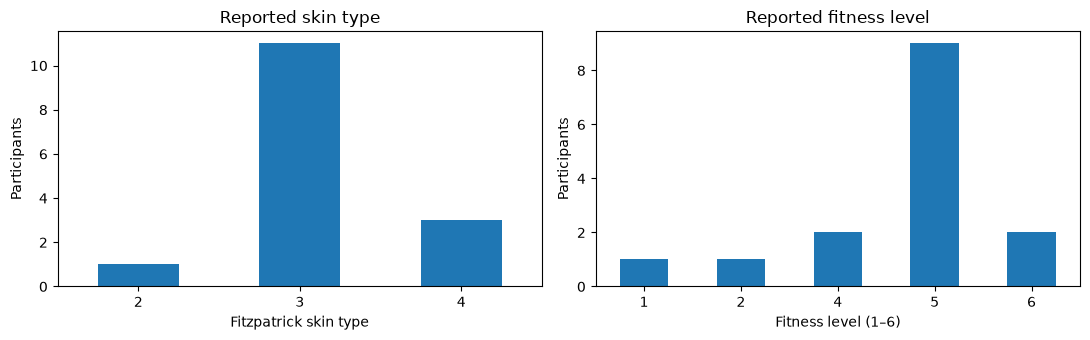

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

subjects["Skin type"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Reported skin type", xlabel="Fitzpatrick skin type", ylabel="Participants")

subjects["Fitness"].value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Reported fitness level", xlabel="Fitness level (1–6)", ylabel="Participants")

plt.tight_layout()
plt.show()

## 2. Choose a participant

Change only `SUBJECT` to examine someone else. `DATA_FOLDER` should point to the extracted folder containing `S1/`, `S2/`, etc. The relative path below assumes the notebook lives in `notebooks/` and the extracted dataset lives in `data/PPG_FieldStudy/`.

**Suggested first choice:** S1 is a reasonable starting point. S6 has a shortened recording because of a hardware issue; S5 has unusually high average reference heart rate in the original study. Those can make useful comparisons later.

In [138]:
SUBJECTS = ["S1", "S4"]  # Compare many subjects
# SUBJECTS = ["S1"]      # Analyze only S1
DATA_FOLDER = Path("../Data/PPG_FieldStudy")


# Show the selected participant's published metadata.
display(subjects[subjects["Subject"].isin(SUBJECTS)])

,Subject,Gender,Age,Height (cm),Weight (kg),Skin type,Fitness
0,S1,Male,34,182,78,3,6
3,S4,Male,25,168,57,4,5


## 3. Load the selected person's recordings

We load the wrist BVP/PPG, the wrist accelerometer, and the reference HR labels. **Reference HR is for exploration and later evaluation only; it must never be used to calculate the PPG estimate.**

**Security note:** Python pickle can execute code while loading. Only open `.pkl` files from the trusted official dataset, preferably in an isolated environment.

In [139]:
recordings = {}

PPG_HZ = 64
ACC_HZ = 32

for subject in SUBJECTS:
    file = DATA_FOLDER / subject / f"{subject}.pkl"

    with open(file, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    recordings[subject] = {
        "ppg": np.asarray(data["signal"]["wrist"]["BVP"]).flatten(),
        "acc": np.asarray(data["signal"]["wrist"]["ACC"]),
        "reference_hr": np.asarray(data["label"]).flatten()
    }

    print(f"{subject} loaded successfully")

S1 loaded successfully
S4 loaded successfully


### Sampling rates, durations, and missing values

In [140]:
summary = []

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    acc = recordings[subject]["acc"]
    reference_hr = recordings[subject]["reference_hr"]

    summary.extend([
        [subject, "Wrist PPG", len(ppg), PPG_HZ,
         len(ppg) / PPG_HZ / 60, np.size(ppg) - np.isfinite(ppg).sum()],

        [subject, "Wrist ACC", len(acc), ACC_HZ,
         len(acc) / ACC_HZ / 60, np.size(acc) - np.isfinite(acc).sum()],

        [subject, "Reference HR", len(reference_hr), None,
         None, np.size(reference_hr) - np.isfinite(reference_hr).sum()]
    ])

summary = pd.DataFrame(
    summary,
    columns=["Subject", "Signal", "Samples", "Sampling rate (Hz)",
             "Duration (minutes)", "Non-finite values"]
)

display(summary.round(2))

print("Each reference HR label summarizes an 8-second window; labels are spaced 2 seconds apart.")

,Subject,Signal,Samples,Sampling rate (Hz),Duration (minutes),Non-finite values
0,S1,Wrist PPG,589568,64.0,153.53,0
1,S1,Wrist ACC,294784,32.0,153.53,0
2,S1,Reference HR,4603,NaN,NaN,0
3,S4,Wrist PPG,585600,64.0,152.50,0
4,S4,Wrist ACC,292800,32.0,152.50,0
5,S4,Reference HR,4572,NaN,NaN,0


Each reference HR label summarizes an 8-second window; labels are spaced 2 seconds apart.


## 4. Plot a short wrist-signal segment

An entire 2.5-hour recording is too dense to inspect in one plot. Start with 20 seconds; change `START` and `DURATION` to inspect other intervals.

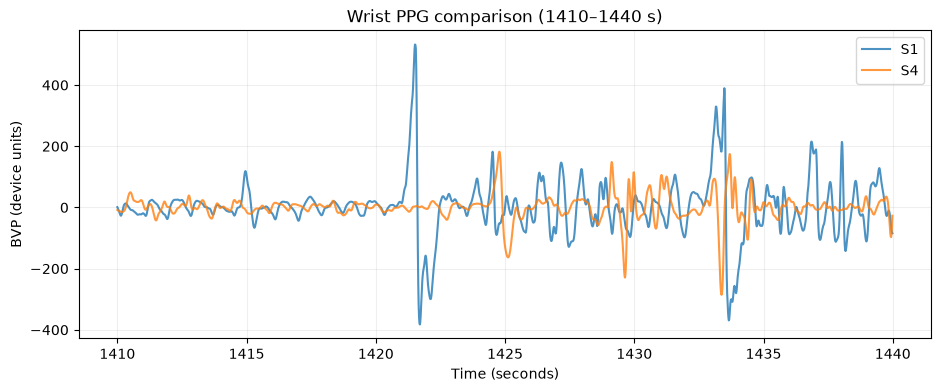

In [141]:
timeline = {"NO:_ACTIVITY1":	0,
 "BASELINE":	90,
 "NO_ACTIVITY2":	791,
 "STAIRS":	837,
 "NO_ACTIVITY3":	1125,
 "SOCCER":	1210,
 "NO_ACTIVITY4":	1556,
 "CYCLING":	1918,
 "NO_ACTIVITY5":	2331,
 "DRIVING":	2935,
 "NO_ACTIVITY6":	3825,
 "LUNCH":	4595,
 "WALKING":	6951,
 "NO_ACTIVITY7":	7706,
 "WORKING":	7791,
 "NO_ACTIVITY8":	8981,
 "CLEAN_BASELINE":	9077,
 "NO_ACTIVITY9":	9198}


START = timeline["SOCCER"] + 200       # seconds from the beginning
# START = timeline["CYCLING"] + 200
DURATION = 30    # seconds to display

plt.figure(figsize=(11, 4))

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]

    start = int(START * PPG_HZ)
    end = int((START + DURATION) * PPG_HZ)
    assert end <= len(ppg), f"{subject}: segment exceeds recording"

    time = np.arange(start, end) / PPG_HZ

    plt.plot(time, ppg[start:end], label=subject, alpha=0.8)

plt.title(f"Wrist PPG comparison ({START}–{START + DURATION} s)")
plt.xlabel("Time (seconds)")
plt.ylabel("BVP (device units)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# BVP = Blood Volume Pulse.
# howa by3ml light kda 3l skin, w yshoof ad eih reflected w ad eih absorbed, w 3la asas kda ye2dar 
# y-estimate el pulses (heartbeat). bs tab3an fy mshakel, en el sha5s byet7arak, fa by7arak el gehaz 3la geldo
# el 7war dh by3ml noise b2a

# 3lshan kda hnla2y spikes hena m3 el spikes el fl wrist acceleration

### Wrist acceleration during the same interval

Compare this visually with the PPG plot. Movement can interfere with PPG, but acceleration alone doesn't prove an individual peak is an artifact.

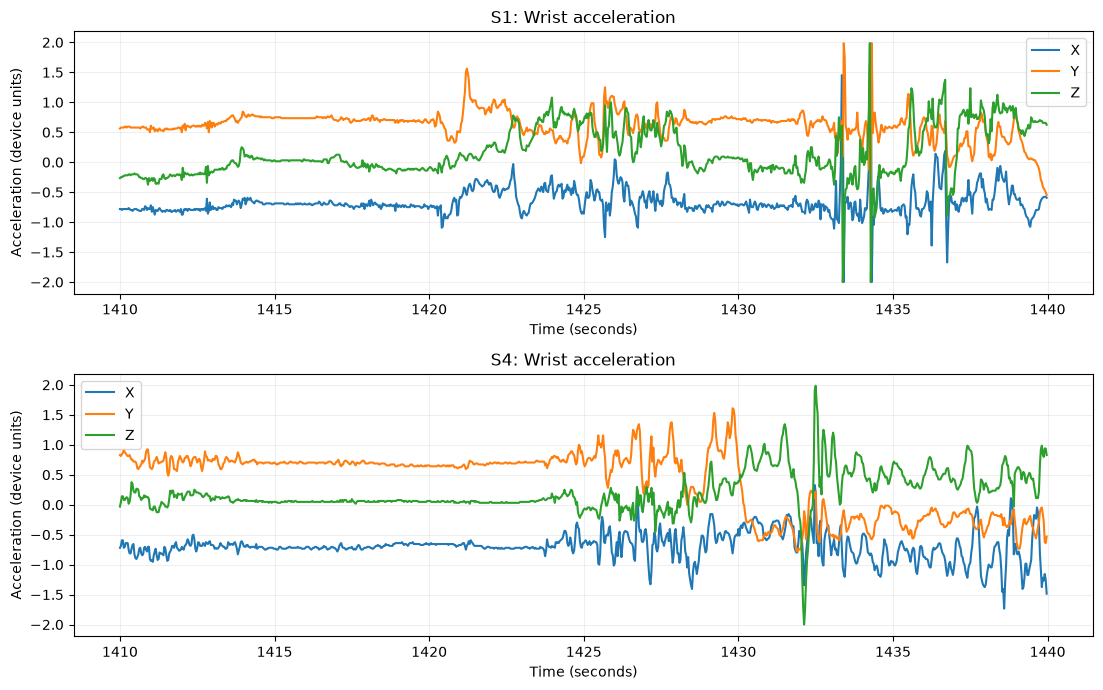

In [142]:
fig, axes = plt.subplots(
    len(SUBJECTS), 1,
    figsize=(11, 3.5 * len(SUBJECTS)),
    squeeze=False
)

for i, subject in enumerate(SUBJECTS):
    acc = recordings[subject]["acc"]

    start = int(START * ACC_HZ)
    end = int((START + DURATION) * ACC_HZ)
    assert end <= len(acc), f"{subject}: segment exceeds recording"

    time = np.arange(start, end) / ACC_HZ

    ax = axes[i, 0]

    for j, axis in enumerate(["X", "Y", "Z"]):
        ax.plot(time, acc[start:end, j], label=axis)

    ax.set_title(f"{subject}: Wrist acceleration")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Acceleration (device units)")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# For table soccer, el spikes dyh 8albn lama byegy y-shoot bl la3eeb bta3o aw yosod aw kda
# wl 7arakat el fag2a el fy kol el axes dyh fl 8aleb byen2el mn rod le rod tanya

## 5. Explore reference heart rate

These labels were obtained from the chest ECG. We look at their distribution **only for understanding and later comparison**, not to estimate HR from PPG.

S1 mean HR: 75.71 BPM
S4 mean HR: 80.74 BPM


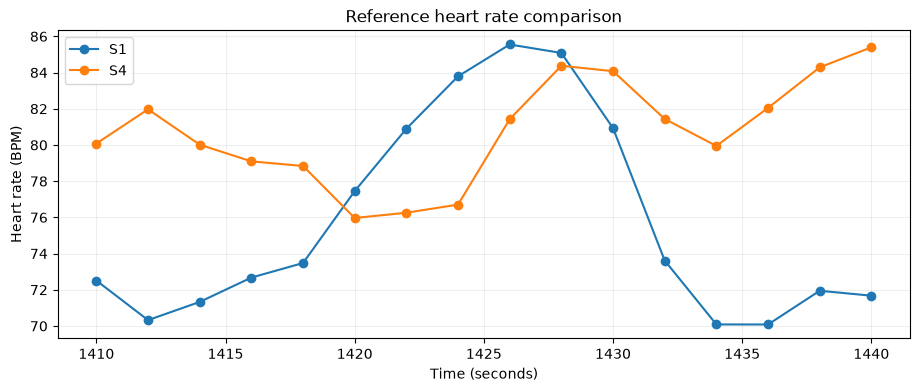

In [143]:
# Reference HR: 8-second windows, shifted by 2 seconds
plt.figure(figsize=(11, 4))

for subject in SUBJECTS:
    reference_hr = recordings[subject]["reference_hr"]

    time = np.arange(len(reference_hr)) * 2 + 4
    mask = (time >= START) & (time <= START + DURATION)

    plt.plot(time[mask], reference_hr[mask],
             marker="o", label=subject)

    print(f"{subject} mean HR: {reference_hr[mask].mean():.2f} BPM")

plt.title("Reference heart rate comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Heart rate (BPM)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# S1 wa2t el table soccer el average kan 75 3ady
# S1 wa2t el cycling el average kan 100 bpm


S1:
count    4603.0
mean       74.8
std        16.2
min        41.9
25%        65.5
50%        71.8
75%        83.3
max       150.2
dtype: float64

S4:
count    4572.0
mean       87.9
std        13.0
min        56.2
25%        80.5
50%        86.7
75%        94.8
max       132.0
dtype: float64


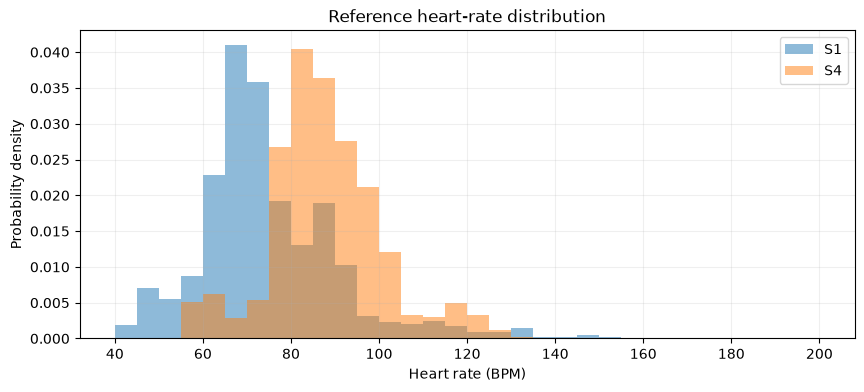

In [144]:
plt.figure(figsize=(10, 4))

for subject in SUBJECTS:
    reference_hr = recordings[subject]["reference_hr"]
    valid_hr = reference_hr[np.isfinite(reference_hr)]

    plt.hist(valid_hr, bins=np.arange(40, 201, 5),
             alpha=0.5, density=True, label=subject)

    print(f"\n{subject}:")
    print(pd.Series(valid_hr).describe().round(1))

plt.title("Reference heart-rate distribution")
plt.xlabel("Heart rate (BPM)")
plt.ylabel("Probability density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
# bna5od el heart rate mn el gehaz el tany (el by2ees darabat el 2alb 3la tool) 3la window
# 8 thwany. w shift 2 kol mara. w h3mlna histogram lel kalam dh